# Preparación del entorno
El primer paso será instalar las bibliotecas necesarias.

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import zipfile
import os

zip_path = '/content/drive/MyDrive/archive.zip'
if os.path.exists(zip_path):
    print("Descomprimiendo el dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('./')
    print("¡Descompresión completada!")
else:
    print("Por favor, sube el archivo zip del dataset a Colab primero.")

Descomprimiendo el dataset...
¡Descompresión completada!


# Cargar y visualizar las imágenes
Para comprobar que las imágenes se han cargado correctamente visualizaremos algunas. Además, se cargarán las imágenes en lotes de tamaño 4.

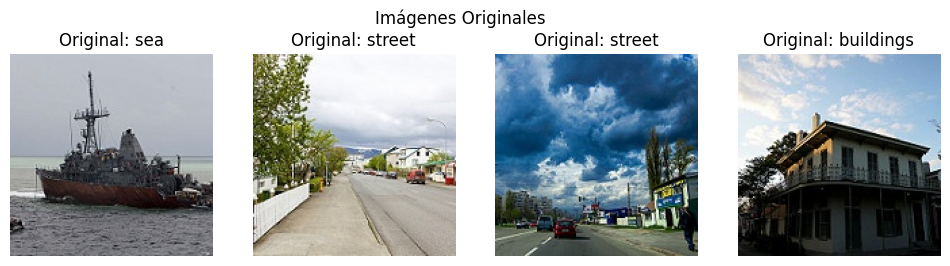

In [12]:
base_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor()
])

train_dir = './seg_train/seg_train'
test_dir = './seg_test/seg_test'

train_data = datasets.ImageFolder(train_dir, transform=base_transform)
test_data = datasets.ImageFolder(test_dir, transform=base_transform)

train_loader = DataLoader(
    train_data,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
test_loader = DataLoader(
    test_data,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

def imshow(img, title):
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(title)
    plt.axis('off')

dataiter = iter(train_loader)
images, labels = next(dataiter)

fig = plt.figure(figsize=(12, 3))
for i in range(4):
    ax = fig.add_subplot(1, 4, i+1)
    imshow(images[i], f'Original: {train_data.classes[labels[i]]}')
plt.suptitle("Imágenes Originales")
plt.show()

# Aumento de imágenes
Se aplican 5 técnicas de aumento a las imágenes.

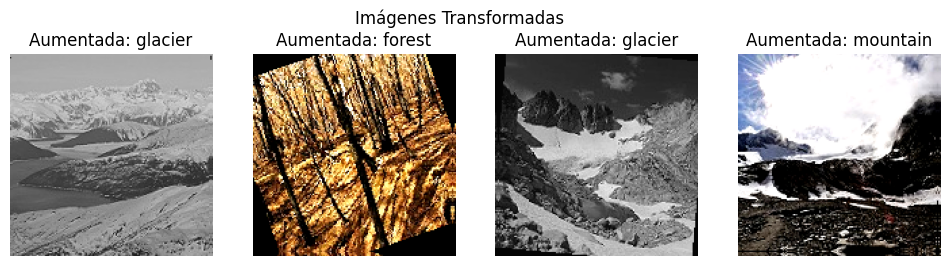

In [13]:
train_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(p=0.5),                        # 1. Flip horizontal
    transforms.RandomRotation(degrees=20),                         # 2. Rotaciones aleatorias
    transforms.ColorJitter(brightness=0.3, contrast=0.3),          # 3. Cambios en el brillo
    transforms.RandomCrop(150, padding=4, padding_mode='reflect'), # 4. Recortes aleatorios
    transforms.RandomGrayscale(p=0.2),                             # 5. Escala de grises parcial
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

train_data.transform = train_transforms

test_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])
test_data.transform = test_transforms

dataiter_aug = iter(train_loader)
images_aug, labels_aug = next(dataiter_aug)

fig = plt.figure(figsize=(12, 3))
for i in range(4):
    ax = fig.add_subplot(1, 4, i+1)
    img_desnorm = images_aug[i] / 2 + 0.5
    imshow(img_desnorm, f'Aumentada: {train_data.classes[labels_aug[i]]}')
plt.suptitle("Imágenes Transformadas")
plt.show()

# Definir y entrenar la red convolucional
Diseñamos una CNN con dos capas convulocionales con funciones de activación ReLU, capas de MaxPooling y totalmente conectadas.

Además, se utilizará CrossEntropyLoss como criterio de pérdida, adecuado para las tareas de clasificación.

In [14]:
class CNN(nn.Module):
    def __init__(self, num_classes=6):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(32 * 37 * 37, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 37 * 37) # Flatten
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN(num_classes=len(train_data.classes)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

epochs = 30
print("Iniciando entrenamiento...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    print(f"Época [{epoch+1}/{epochs}] - Pérdida: {epoch_loss:.4f}")

Iniciando entrenamiento...
Época [1/30] - Pérdida: 1.0224
Época [2/30] - Pérdida: 0.7839
Época [3/30] - Pérdida: 0.6993
Época [4/30] - Pérdida: 0.6467
Época [5/30] - Pérdida: 0.6026
Época [6/30] - Pérdida: 0.5727
Época [7/30] - Pérdida: 0.5487
Época [8/30] - Pérdida: 0.5382
Época [9/30] - Pérdida: 0.5169
Época [10/30] - Pérdida: 0.4988
Época [11/30] - Pérdida: 0.4813
Época [12/30] - Pérdida: 0.4714
Época [13/30] - Pérdida: 0.4663
Época [14/30] - Pérdida: 0.4529
Época [15/30] - Pérdida: 0.4469
Época [16/30] - Pérdida: 0.4294
Época [17/30] - Pérdida: 0.4227
Época [18/30] - Pérdida: 0.4082
Época [19/30] - Pérdida: 0.4089
Época [20/30] - Pérdida: 0.4053
Época [21/30] - Pérdida: 0.3947
Época [22/30] - Pérdida: 0.3760
Época [23/30] - Pérdida: 0.3735
Época [24/30] - Pérdida: 0.3670
Época [25/30] - Pérdida: 0.3648
Época [26/30] - Pérdida: 0.3589
Época [27/30] - Pérdida: 0.3568
Época [28/30] - Pérdida: 0.3480
Época [29/30] - Pérdida: 0.3373
Época [30/30] - Pérdida: 0.3399


# Evaluación del modelo
Tras entrenar el modelo el último paso será evaluar su rendimiento.

In [15]:
model.eval()
test_loss = 0.0
correct = 0
total = 0

print("Evaluando el modelo con imágenes sin aumento...")
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

avg_test_loss = test_loss / len(test_loader)
accuracy = 100 * correct / total

print(f"Pérdida en Evaluación (Loss): {avg_test_loss:.4f}")
print(f"Precisión (Accuracy): {accuracy:.2f}%")

Evaluando el modelo con imágenes sin aumento...
Pérdida en Evaluación (Loss): 0.4202
Precisión (Accuracy): 85.73%
